In [1]:
!pip install -q fsspec-xrootd xrootd

In [2]:
import argparse
import sys

import awkward as ak
import numpy as np
import uproot
import vector

vector.register_awkward()

In [7]:
from pathlib import Path
data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# 1. Print all root files
root_files = sorted(list(data_dir.glob("*.root")))
print(f"Found {len(root_files)} ROOT files:")
for rf in root_files:
    print(" -", rf.name)

# 2. Inspect branches in the first file
if root_files:
    with uproot.open(root_files[0]) as f:
        tree = f["Events"]
        print(f"\nTotal events in {root_files[0].name}: {tree.num_entries}")
        print("\nAvailable feature branches:")
        print(tree.keys()[:25], f"... (+ {len(tree.keys()) - 25} more)" if len(tree.keys()) > 25 else "")

Found 8 ROOT files:
 - DY-test.root
 - DY-train.root
 - Higgs-test.root
 - Higgs-train.root
 - Top-test.root
 - Top-train.root
 - WW-test.root
 - WW-train.root

Total events in DY-test.root: 16064629

Available feature branches:
['Electron_charge', 'Electron_eta', 'Electron_mass', 'Electron_mvaFall17V2Iso_WP90', 'Electron_phi', 'Electron_pt', 'Jet_btagDeepFlavB', 'Jet_eta', 'Jet_jetId', 'Jet_mass', 'Jet_phi', 'Jet_pt', 'Jet_puId', 'Muon_charge', 'Muon_eta', 'Muon_mass', 'Muon_pfRelIso04_all', 'Muon_phi', 'Muon_pt', 'Muon_tightId', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'mjj', 'mll'] ... (+ 4 more)


In [4]:
files = "/data/bvcoe2026/CMS-OD/samples$"
path = "/data/bvcoe2026/CMS-OD/samples/Higgs-test.root/"

Number of entries: 383958
Minimum: 0.00783682
Maximum: 392.7699


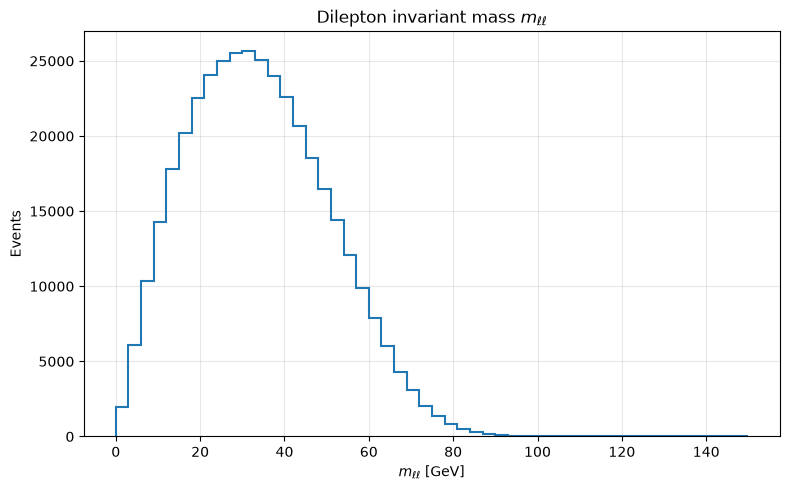

In [6]:
import matplotlib.pyplot as plt
import numpy as np

with uproot.open(path) as f:
    mll = f["Events"].arrays(["mll"], library="np")["mll"]

# Remove undefined values
mll = mll[mll > 0]

print("Number of entries:", len(mll))
print("Minimum:", np.min(mll))
print("Maximum:", np.max(mll))

plt.figure(figsize=(8, 5))

plt.hist(
    mll,
    bins=50,
    range=(0, 150),
    histtype="step",
    linewidth=1.5
)

plt.xlabel(r"$m_{\ell\ell}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Dilepton invariant mass $m_{\ell\ell}$")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Number of entries: 192206
Minimum: 0.0
Maximum: 3.14151


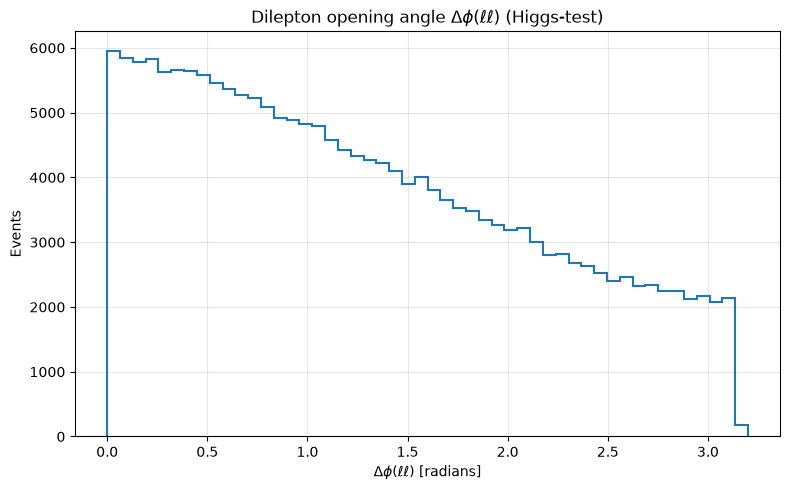

In [15]:
import matplotlib.pyplot as plt
import numpy as np

path = "/data/bvcoe2026/CMS-OD/samples/Higgs-test.root"

with uproot.open(path) as f:
    dphi = f["Events"].arrays(["dphill"], library="np")["dphill"]

# Keep physical values between 0 and pi (3.14)
dphi = dphi[(dphi >= 0) & (dphi <= 3.2)]

print("Number of entries:", len(dphi))
print("Minimum:", np.min(dphi))
print("Maximum:", np.max(dphi))

plt.figure(figsize=(8, 5))
plt.hist(dphi, bins=50, range=(0, 3.2), histtype="step", linewidth=1.5)
plt.xlabel(r"$\Delta\phi(\ell\ell)$ [radians]")
plt.ylabel("Events")
plt.title(r"Dilepton opening angle $\Delta\phi(\ell\ell)$ (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 1507000
Minimum: 0.035993762
Maximum: 1172.4607


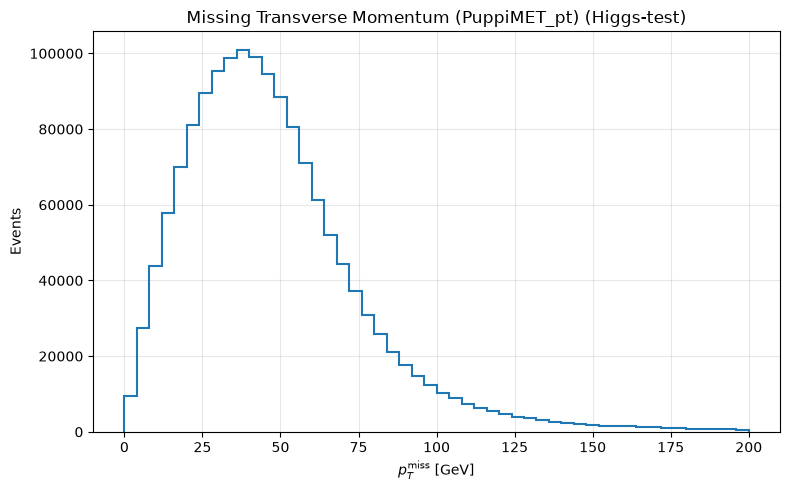

In [17]:
with uproot.open(path) as f:
    met = f["Events"].arrays(["PuppiMET_pt"], library="np")["PuppiMET_pt"]

# Filter out unphysical negative values
met = met[met >= 0]

print("Number of entries:", len(met))
print("Minimum:", np.min(met))
print("Maximum:", np.max(met))

plt.figure(figsize=(8, 5))
plt.hist(met, bins=50, range=(0, 200), histtype="step", linewidth=1.5)
plt.xlabel(r"$p_T^{\mathrm{miss}}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Missing Transverse Momentum (PuppiMET_pt) (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 383958
Minimum: 0.07683305
Maximum: 936.4624


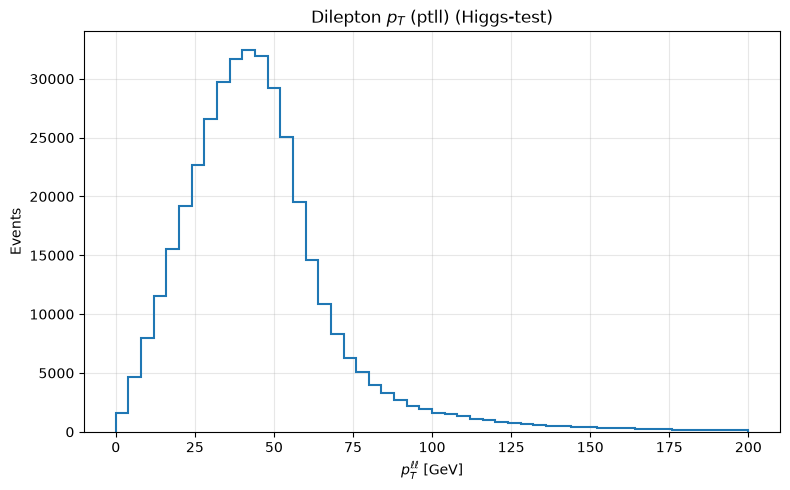

In [19]:
with uproot.open(path) as f:
    ptll = f["Events"].arrays(["ptll"], library="np")["ptll"]

ptll = ptll[ptll >= 0]

print("Number of entries:", len(ptll))
print("Minimum:", np.min(ptll))
print("Maximum:", np.max(ptll))

plt.figure(figsize=(8, 5))
plt.hist(ptll, bins=50, range=(0, 200), histtype="step", linewidth=1.5)
plt.xlabel(r"$p_T^{\ell\ell}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Dilepton $p_T$ (ptll) (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 383958
Minimum: 5.815304e-05
Maximum: 546.9156


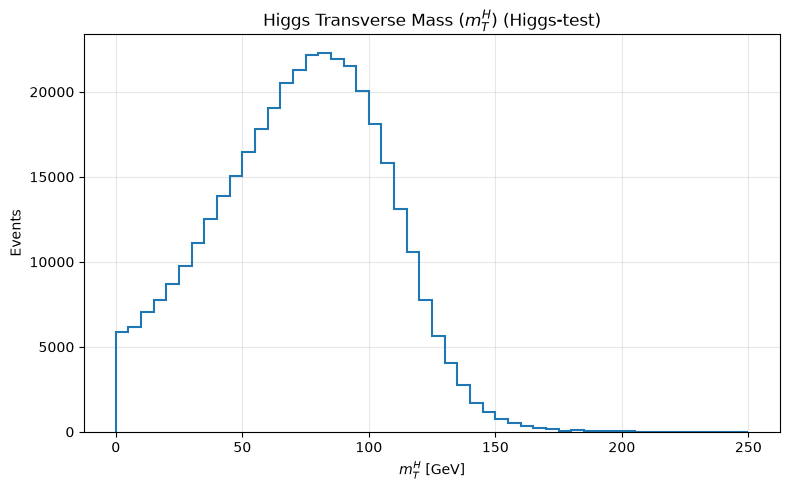

In [21]:
with uproot.open(path) as f:
    mth = f["Events"].arrays(["mth"], library="np")["mth"]

mth = mth[mth > 0]

print("Number of entries:", len(mth))
print("Minimum:", np.min(mth))
print("Maximum:", np.max(mth))

plt.figure(figsize=(8, 5))
plt.hist(mth, bins=50, range=(0, 250), histtype="step", linewidth=1.5)
plt.xlabel(r"$m_T^H$ [GeV]")
plt.ylabel("Events")
plt.title(r"Higgs Transverse Mass ($m_T^H$) (Higgs-test)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of entries: 1507000
Minimum jets: 0
Maximum jets: 19


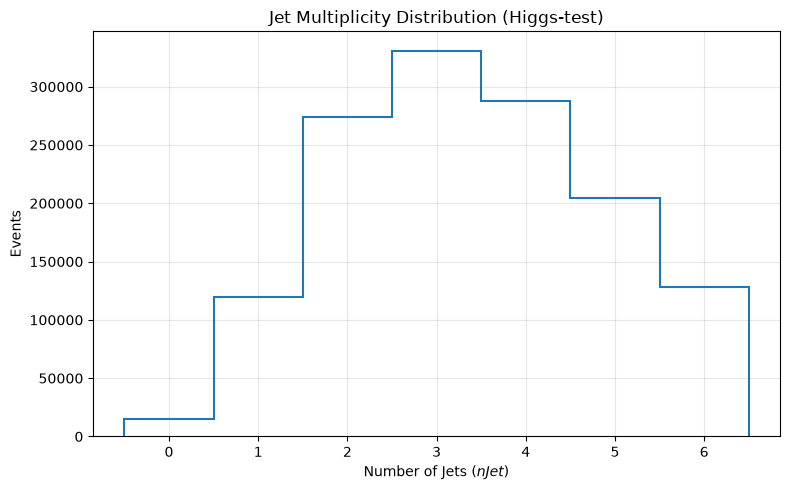

In [23]:
with uproot.open(path) as f:
    njet = f["Events"].arrays(["nJet"], library="np")["nJet"]

print("Number of entries:", len(njet))
print("Minimum jets:", np.min(njet))
print("Maximum jets:", np.max(njet))

plt.figure(figsize=(8, 5))
# Discrete bins from 0 to 6 jets
plt.hist(njet, bins=7, range=(-0.5, 6.5), histtype="step", linewidth=1.5, rwidth=0.8)
plt.xlabel("Number of Jets ($nJet$)")
plt.ylabel("Events")
plt.title("Jet Multiplicity Distribution (Higgs-test)")
plt.xticks(range(7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Open the file
f = uproot.open("/data/bvcoe2026/CMS-OD/samples/Higgs-train.root")

# List the contents (keys)
print("Keys inside the file:")
print(f.keys())

Keys inside the file:
['Events;1']


In [10]:
tree = f["Events"]

print(f"Total collision events (rows): {tree.num_entries}\n")

# Display columns, types, and sizes
tree.show()

Total collision events (rows): 1439000

Events (ROOT::RNTuple)
├─ Electron_charge (std::vector<std::int32_t>)
├─ Electron_eta (std::vector<float>)
├─ Electron_mass (std::vector<float>)
├─ Electron_mvaFall17V2Iso_WP90 (std::vector<bool>)
├─ Electron_phi (std::vector<float>)
├─ Electron_pt (std::vector<float>)
├─ Jet_btagDeepFlavB (std::vector<float>)
├─ Jet_eta (std::vector<float>)
├─ Jet_jetId (std::vector<std::int32_t>)
├─ Jet_mass (std::vector<float>)
├─ Jet_phi (std::vector<float>)
├─ Jet_pt (std::vector<float>)
├─ Jet_puId (std::vector<std::int32_t>)
├─ Muon_charge (std::vector<std::int32_t>)
├─ Muon_eta (std::vector<float>)
├─ Muon_mass (std::vector<float>)
├─ Muon_pfRelIso04_all (std::vector<float>)
├─ Muon_phi (std::vector<float>)
├─ Muon_pt (std::vector<float>)
├─ Muon_tightId (std::vector<bool>)
├─ PuppiMET_phi (float)
├─ PuppiMET_pt (float)
├─ dphill (float)
├─ mjj (float)
├─ mll (float)
├─ mth (float)
├─ mtw2 (float)
├─ nJet (std::uint32_t)
└─ ptll (float)


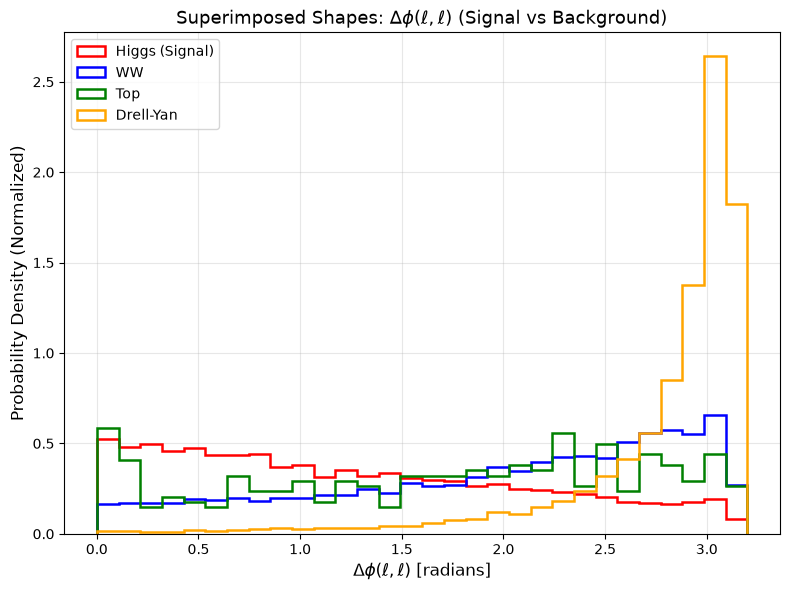

In [11]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# The four physics processes
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW": ("WW-train.root", "blue"),
    "Top": ("Top-train.root", "green"),
    "Drell-Yan": ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        # Load up to 100,000 events to keep it fast and prevent memory overload
        tree = f["Events"]
        dphi = tree.arrays(["dphill"], library="np", entry_stop=100000)["dphill"]
        
        # Filter valid values (angles between 0 and pi)
        valid = (dphi >= 0) & (dphi <= 3.2)
        dphi = dphi[valid]

        # Superimpose normalized histogram (density=True sets unit area)
        plt.hist(
            dphi,
            bins=30,
            range=(0, 3.2),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$\Delta\phi(\ell, \ell)$ [radians]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: $\Delta\phi(\ell, \ell)$ (Signal vs Background)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

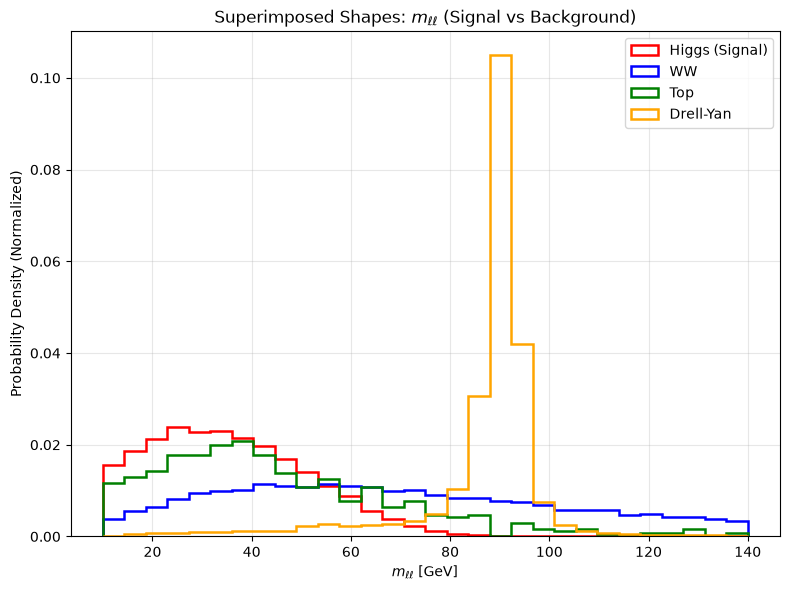

In [25]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# The four physics processes
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW": ("WW-train.root", "blue"),
    "Top": ("Top-train.root", "green"),
    "Drell-Yan": ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        mll = tree.arrays(["mll"], library="np", entry_stop=100000)["mll"]
        
        # Filter valid values between 10 and 140 GeV
        valid = (mll >= 10) & (mll <= 140)
        mll = mll[valid]

        # Superimpose normalized histogram
        plt.hist(
            mll,
            bins=30,
            range=(10, 140),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$m_{\ell\ell}$ [GeV]")
plt.ylabel("Probability Density (Normalized)")
plt.title(r"Superimposed Shapes: $m_{\ell\ell}$ (Signal vs Background)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

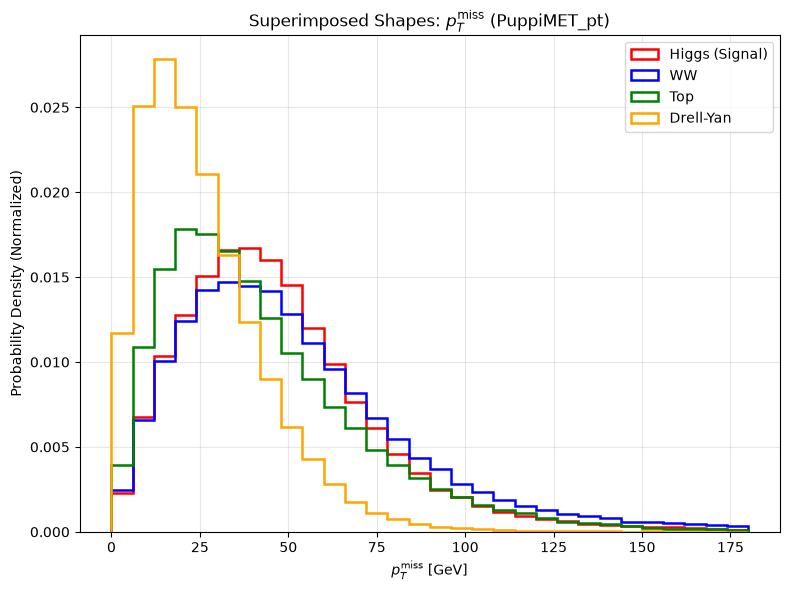

In [26]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# The four physics processes
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW": ("WW-train.root", "blue"),
    "Top": ("Top-train.root", "green"),
    "Drell-Yan": ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        met = tree.arrays(["PuppiMET_pt"], library="np", entry_stop=100000)["PuppiMET_pt"]
        
        # Filter valid values between 0 and 180 GeV
        valid = (met >= 0) & (met <= 180)
        met = met[valid]

        # Superimpose normalized histogram
        plt.hist(
            met,
            bins=30,
            range=(0, 180),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$p_T^{\mathrm{miss}}$ [GeV]")
plt.ylabel("Probability Density (Normalized)")
plt.title(r"Superimposed Shapes: $p_T^{\mathrm{miss}}$ (PuppiMET_pt)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

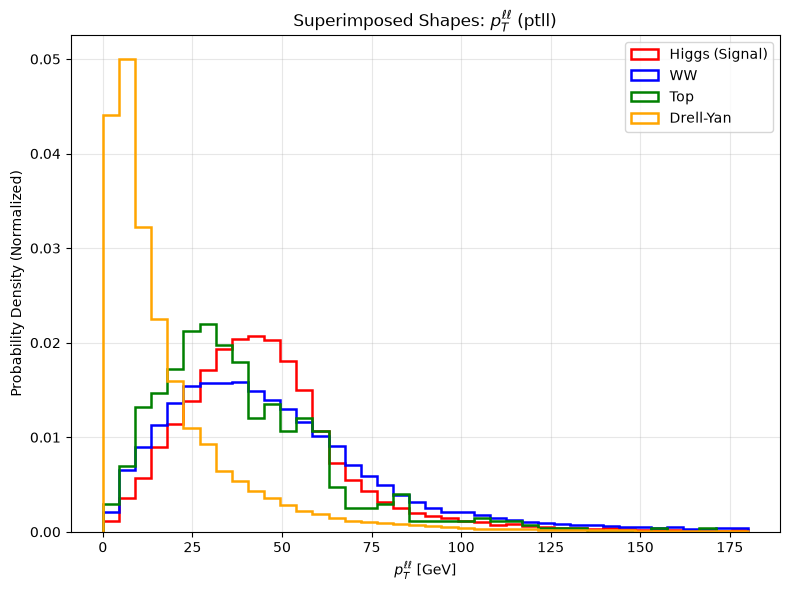

In [28]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# The four physics processes
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW": ("WW-train.root", "blue"),
    "Top": ("Top-train.root", "green"),
    "Drell-Yan": ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        ptll = tree.arrays(["ptll"], library="np", entry_stop=100000)["ptll"]
        
        # Filter valid values between 0 and 180 GeV
        valid = (ptll >= 0) & (ptll <= 180)
        ptll = ptll[valid]

        # Superimpose normalized histogram
        plt.hist(
            ptll,
            bins=40,
            range=(0, 180),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$p_T^{\ell\ell}$ [GeV]")
plt.ylabel("Probability Density (Normalized)")
plt.title(r"Superimposed Shapes: $p_T^{\ell\ell}$ (ptll)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

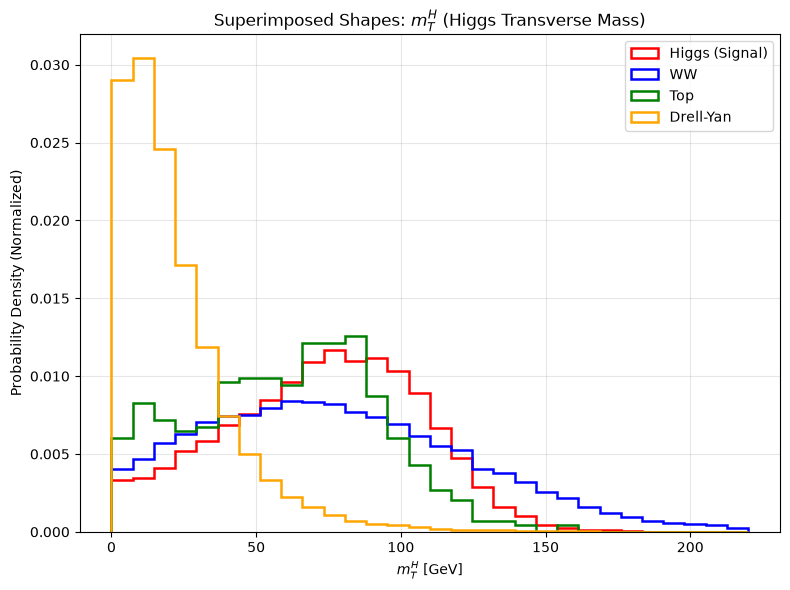

In [29]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# The four physics processes
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW": ("WW-train.root", "blue"),
    "Top": ("Top-train.root", "green"),
    "Drell-Yan": ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        mth = tree.arrays(["mth"], library="np", entry_stop=100000)["mth"]
        
        # Filter valid values between 0 and 220 GeV
        valid = (mth >= 0) & (mth <= 220)
        mth = mth[valid]

        # Superimpose normalized histogram
        plt.hist(
            mth,
            bins=30,
            range=(0, 220),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$m_T^H$ [GeV]")
plt.ylabel("Probability Density (Normalized)")
plt.title(r"Superimposed Shapes: $m_T^H$ (Higgs Transverse Mass)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

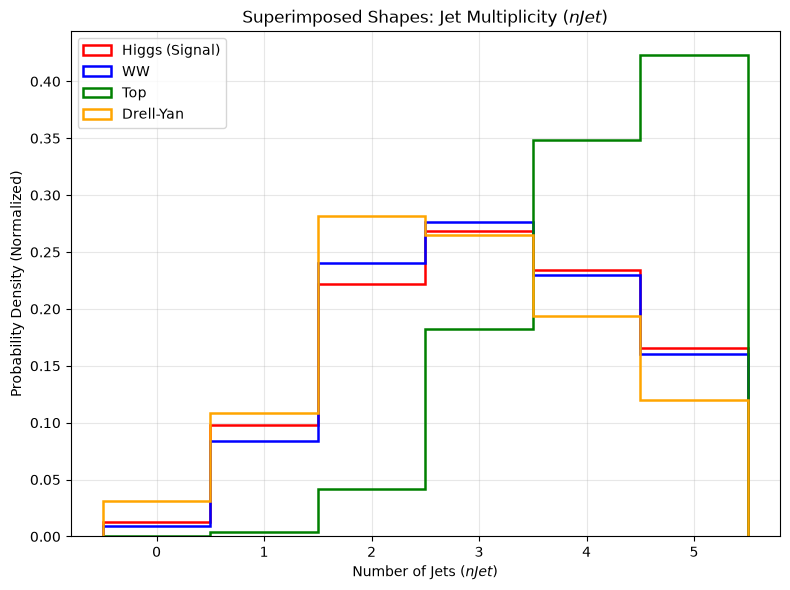

In [30]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

# The four physics processes
samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW": ("WW-train.root", "blue"),
    "Top": ("Top-train.root", "green"),
    "Drell-Yan": ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        njet = tree.arrays(["nJet"], library="np", entry_stop=100000)["nJet"]
        
        # Keep 0 to 5 jets
        valid = (njet >= 0) & (njet <= 5)
        njet = njet[valid]

        # Superimpose normalized histogram
        plt.hist(
            njet,
            bins=6,
            range=(-0.5, 5.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Number of Jets ($nJet$)")
plt.ylabel("Probability Density (Normalized)")
plt.title("Superimposed Shapes: Jet Multiplicity ($nJet$)")
plt.xticks(range(6))
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

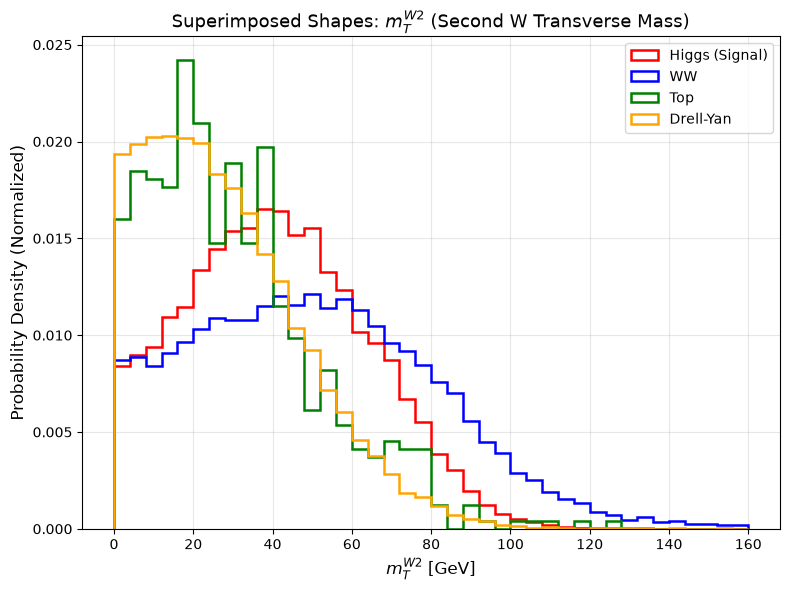

In [31]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        mtw2 = tree.arrays(["mtw2"], library="np", entry_stop=100000)["mtw2"]
        
        valid = (mtw2 >= 0) & (mtw2 <= 160)
        mtw2 = mtw2[valid]

        plt.hist(
            mtw2,
            bins=40,
            range=(0, 160),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$m_T^{W2}$ [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: $m_T^{W2}$ (Second W Transverse Mass)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

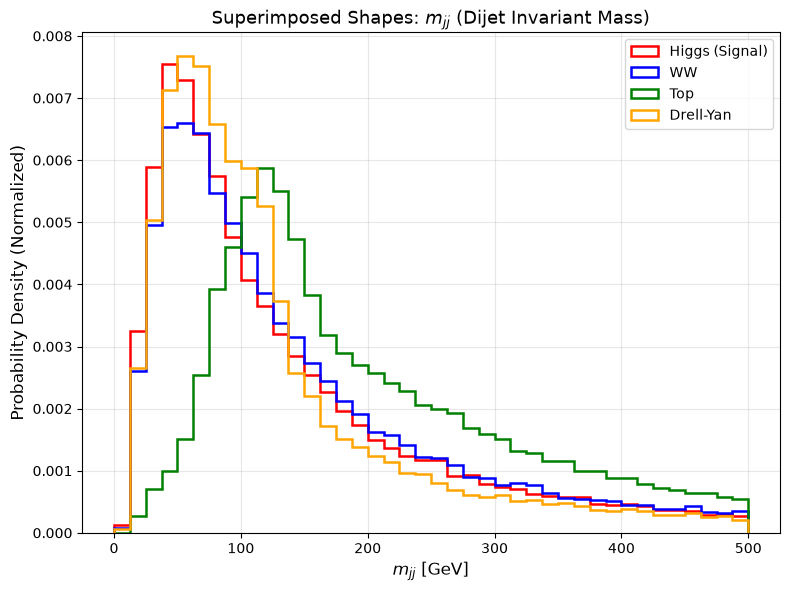

In [32]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        mjj = tree.arrays(["mjj"], library="np", entry_stop=100000)["mjj"]
        
        # Keep positive mass values where 2 jets actually exist
        valid = (mjj > 0) & (mjj <= 500)
        mjj = mjj[valid]

        plt.hist(
            mjj,
            bins=40,
            range=(0, 500),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$m_{jj}$ [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: $m_{jj}$ (Dijet Invariant Mass)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

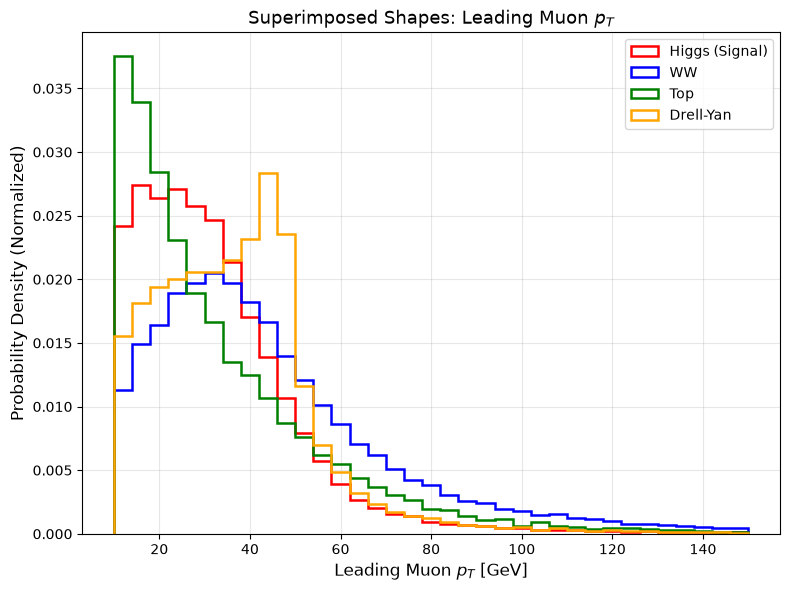

In [33]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        # Read as awkward array to handle variable-length lists
        mu_pt_jagged = tree.arrays(["Muon_pt"], library="ak", entry_stop=100000)["Muon_pt"]
        
        # Pick the leading muon (first entry per event), drop events with no muons
        leading_mu_pt = ak.to_numpy(ak.firsts(mu_pt_jagged))
        valid_mask = ~np.isnan(leading_mu_pt) & (leading_mu_pt >= 10) & (leading_mu_pt <= 150)
        leading_mu_pt = leading_mu_pt[valid_mask]

        plt.hist(
            leading_mu_pt,
            bins=35,
            range=(10, 150),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Muon $p_T$ [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Muon $p_T$", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

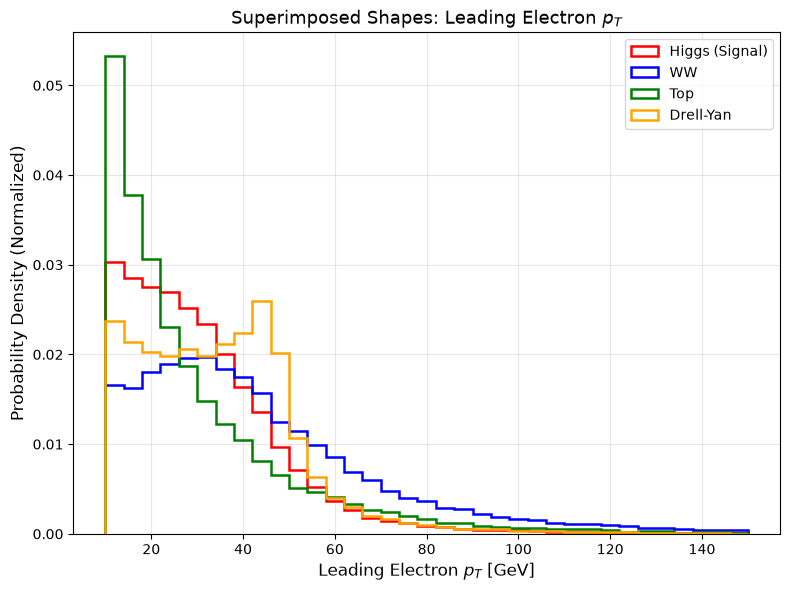

In [34]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        ele_pt_jagged = tree.arrays(["Electron_pt"], library="ak", entry_stop=100000)["Electron_pt"]
        
        # Pick the leading electron (first entry per event)
        leading_ele_pt = ak.to_numpy(ak.firsts(ele_pt_jagged))
        valid_mask = ~np.isnan(leading_ele_pt) & (leading_ele_pt >= 10) & (leading_ele_pt <= 150)
        leading_ele_pt = leading_ele_pt[valid_mask]

        plt.hist(
            leading_ele_pt,
            bins=35,
            range=(10, 150),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Electron $p_T$ [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Electron $p_T$", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

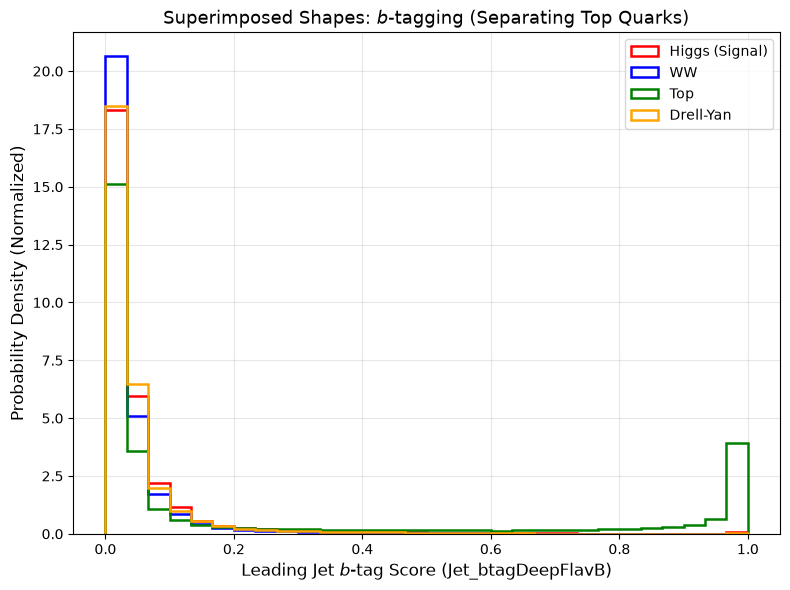

In [35]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        btag_jagged = tree.arrays(["Jet_btagDeepFlavB"], library="ak", entry_stop=100000)["Jet_btagDeepFlavB"]
        
        # Leading jet b-tag score (0 = light jet, 1 = b-quark jet)
        leading_btag = ak.to_numpy(ak.firsts(btag_jagged))
        valid_mask = ~np.isnan(leading_btag) & (leading_btag >= 0.0) & (leading_btag <= 1.0)
        leading_btag = leading_btag[valid_mask]

        plt.hist(
            leading_btag,
            bins=30,
            range=(0.0, 1.0),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Jet $b$-tag Score (Jet_btagDeepFlavB)", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: $b$-tagging (Separating Top Quarks)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

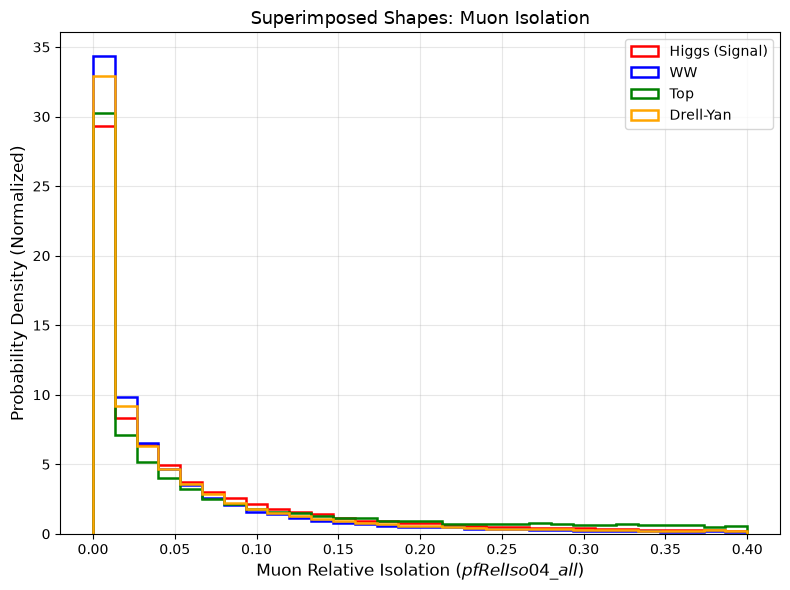

In [36]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        iso_jagged = tree.arrays(["Muon_pfRelIso04_all"], library="ak", entry_stop=100000)["Muon_pfRelIso04_all"]
        
        leading_iso = ak.to_numpy(ak.firsts(iso_jagged))
        valid_mask = ~np.isnan(leading_iso) & (leading_iso >= 0.0) & (leading_iso <= 0.4)
        leading_iso = leading_iso[valid_mask]

        plt.hist(
            leading_iso,
            bins=30,
            range=(0.0, 0.4),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Muon Relative Isolation ($pfRelIso04\_all$)", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Muon Isolation", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

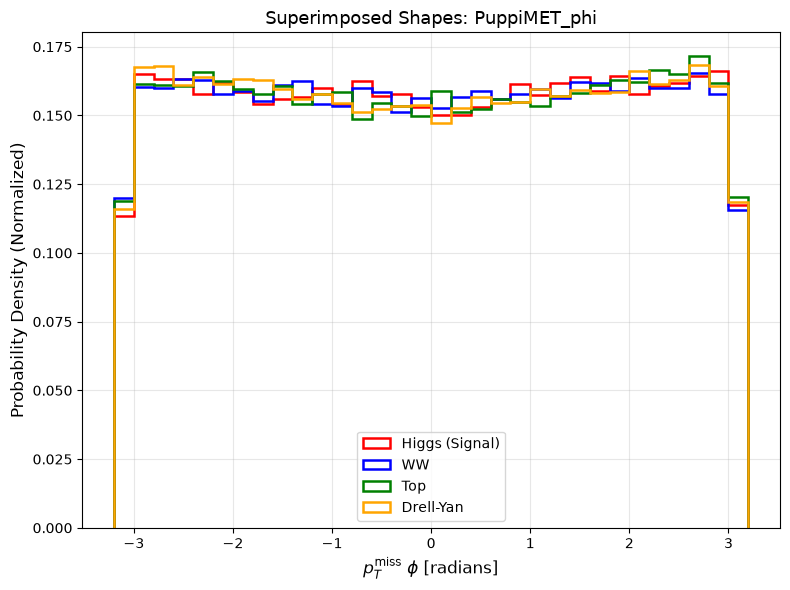

In [37]:
import uproot
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        met_phi = tree.arrays(["PuppiMET_phi"], library="np", entry_stop=100000)["PuppiMET_phi"]
        
        valid = (met_phi >= -3.2) & (met_phi <= 3.2)
        met_phi = met_phi[valid]

        plt.hist(
            met_phi,
            bins=32,
            range=(-3.2, 3.2),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"$p_T^{\mathrm{miss}}\ \phi$ [radians]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: PuppiMET_phi", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

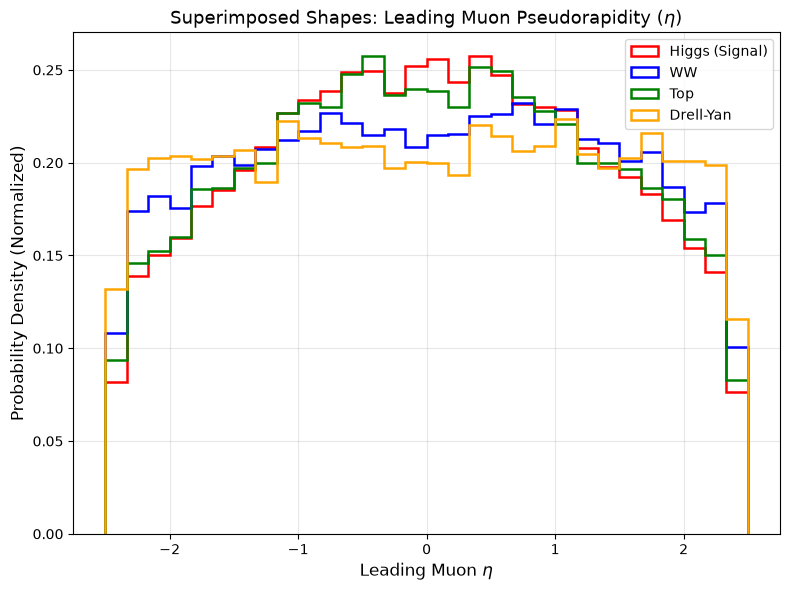

In [38]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Muon_eta"], library="ak", entry_stop=100000)["Muon_eta"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= -2.5) & (leading <= 2.5)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=30,
            range=(-2.5, 2.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Muon $\eta$", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Muon Pseudorapidity ($\eta$)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

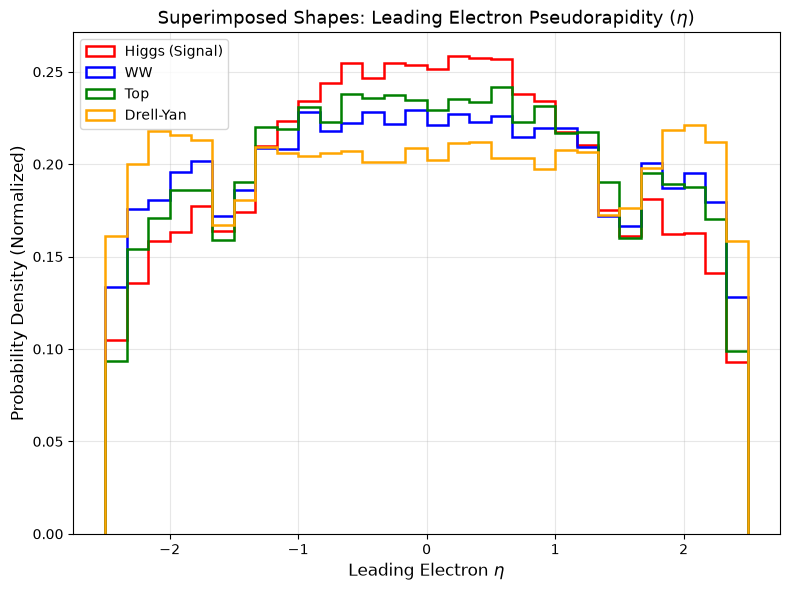

In [39]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        arr = tree.arrays(["Electron_eta"], library="ak", entry_stop=100000)["Electron_eta"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= -2.5) & (leading <= 2.5)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=30,
            range=(-2.5, 2.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Electron $\eta$", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Electron Pseudorapidity ($\eta$)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

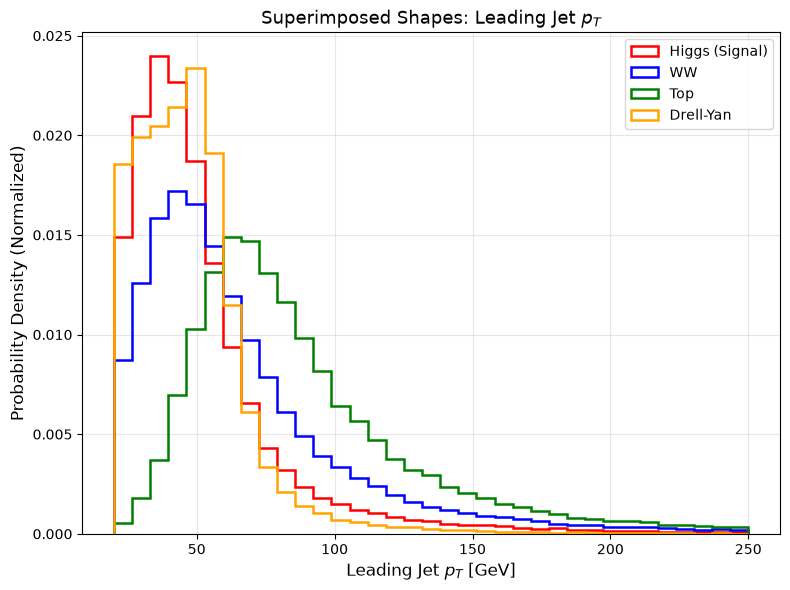

In [40]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Jet_pt"], library="ak", entry_stop=100000)["Jet_pt"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= 20.0) & (leading <= 250.0)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=35,
            range=(20.0, 250.0),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Jet $p_T$ [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Jet $p_T$", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

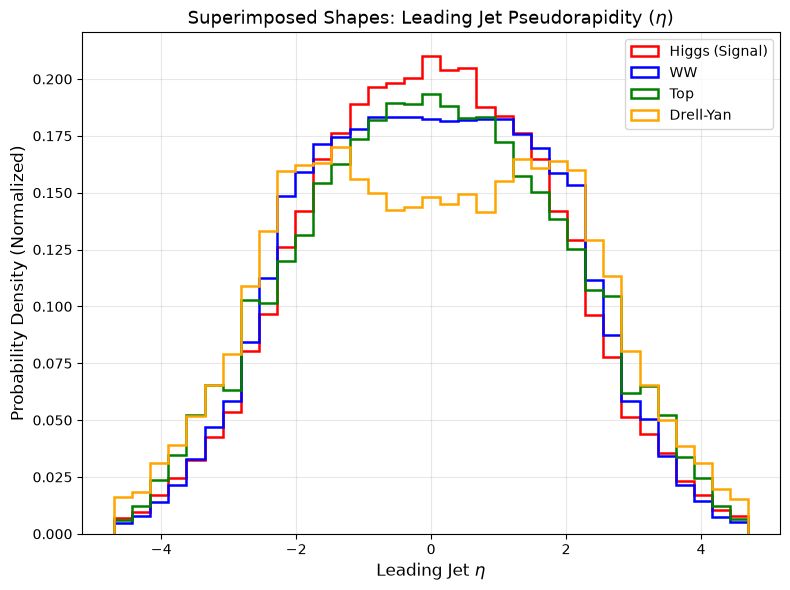

In [41]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Jet_eta"], library="ak", entry_stop=100000)["Jet_eta"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= -4.7) & (leading <= 4.7)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=35,
            range=(-4.7, 4.7),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Jet $\eta$", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Jet Pseudorapidity ($\eta$)", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

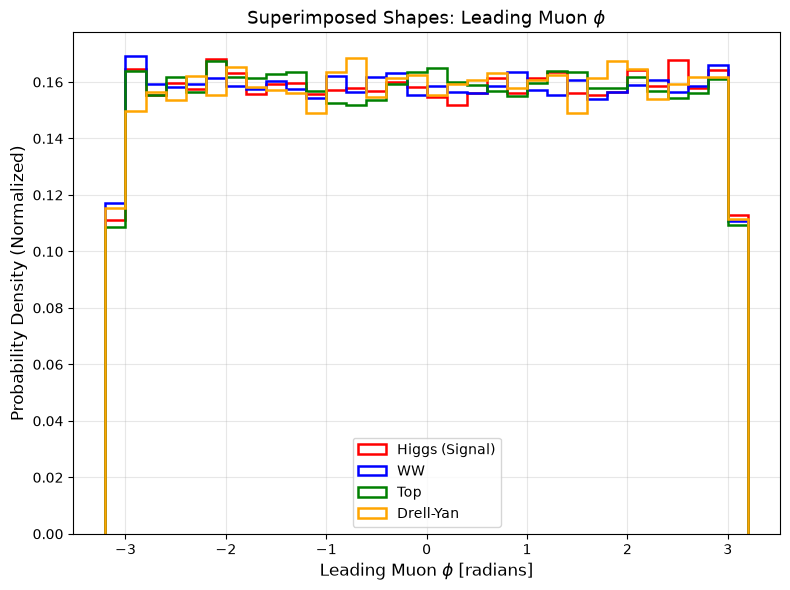

In [42]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Muon_phi"], library="ak", entry_stop=100000)["Muon_phi"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= -3.2) & (leading <= 3.2)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=32,
            range=(-3.2, 3.2),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Muon $\phi$ [radians]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Muon $\phi$", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

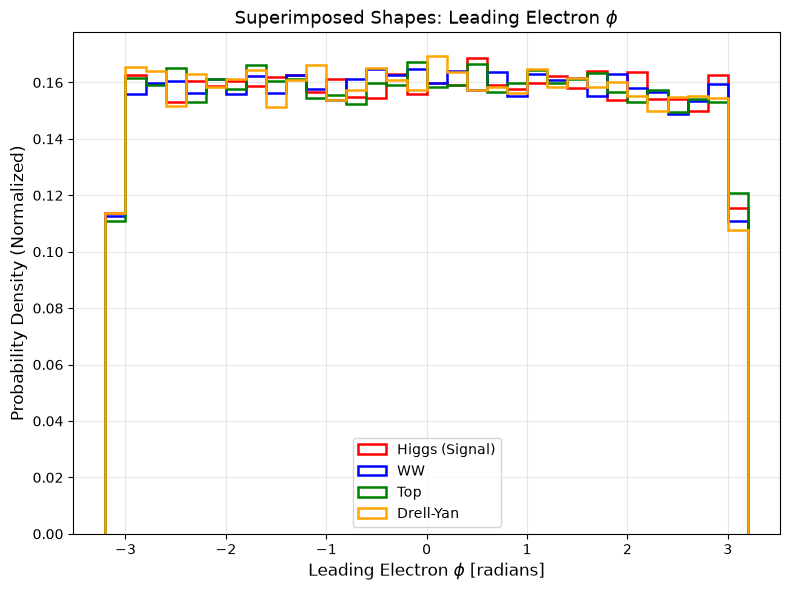

In [43]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Electron_phi"], library="ak", entry_stop=100000)["Electron_phi"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= -3.2) & (leading <= 3.2)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=32,
            range=(-3.2, 3.2),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Electron $\phi$ [radians]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Electron $\phi$", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

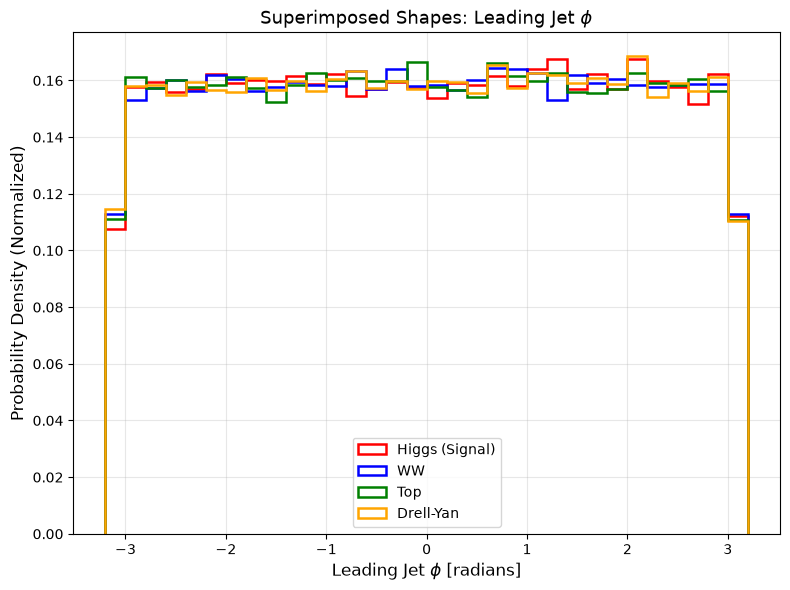

In [44]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Jet_phi"], library="ak", entry_stop=100000)["Jet_phi"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= -3.2) & (leading <= 3.2)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=32,
            range=(-3.2, 3.2),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Jet $\phi$ [radians]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Jet $\phi$", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

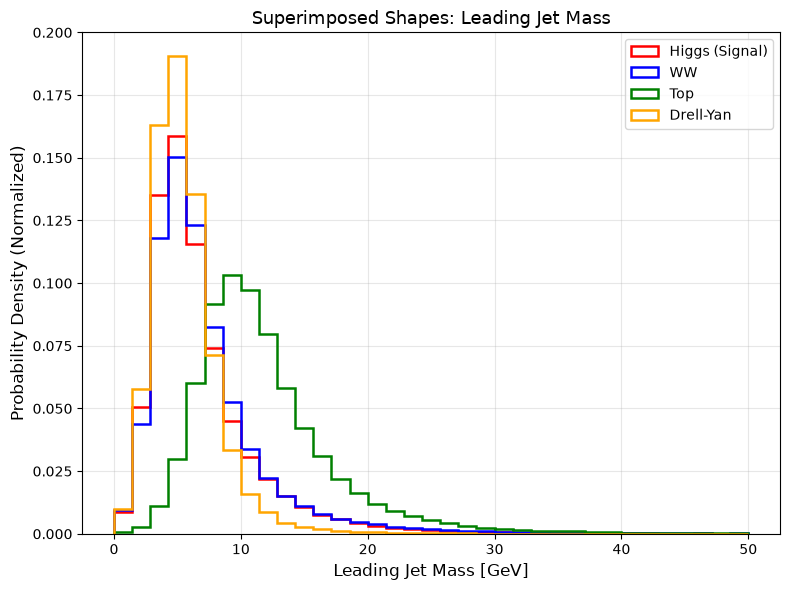

In [45]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Jet_mass"], library="ak", entry_stop=100000)["Jet_mass"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= 0.0) & (leading <= 50.0)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=35,
            range=(0.0, 50.0),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Jet Mass [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Jet Mass", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/tmp/ipykernel_782/1097579294.py:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.xlabel("Leading Muon Charge ($q = \pm 1$)", fontsize=12)


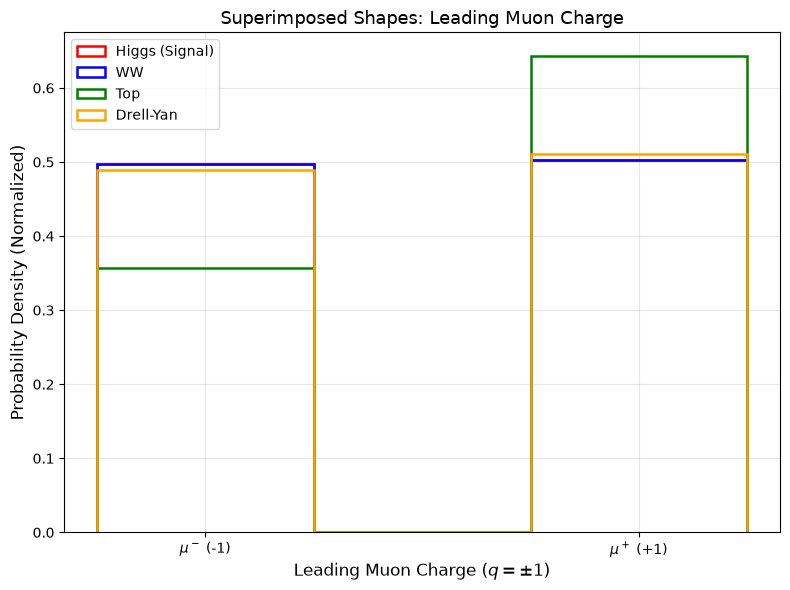

In [46]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Muon_charge"], library="ak", entry_stop=100000)["Muon_charge"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & ((leading == -1) | (leading == 1))
        leading = leading[valid]

        plt.hist(
            leading,
            bins=3,
            range=(-1.5, 1.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Leading Muon Charge ($q = \pm 1$)", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Muon Charge", fontsize=13)
plt.xticks([-1, 1], [r"$\mu^-$ (-1)", r"$\mu^+$ (+1)"])
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/tmp/ipykernel_782/347977453.py:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.xlabel("Leading Electron Charge ($q = \pm 1$)", fontsize=12)


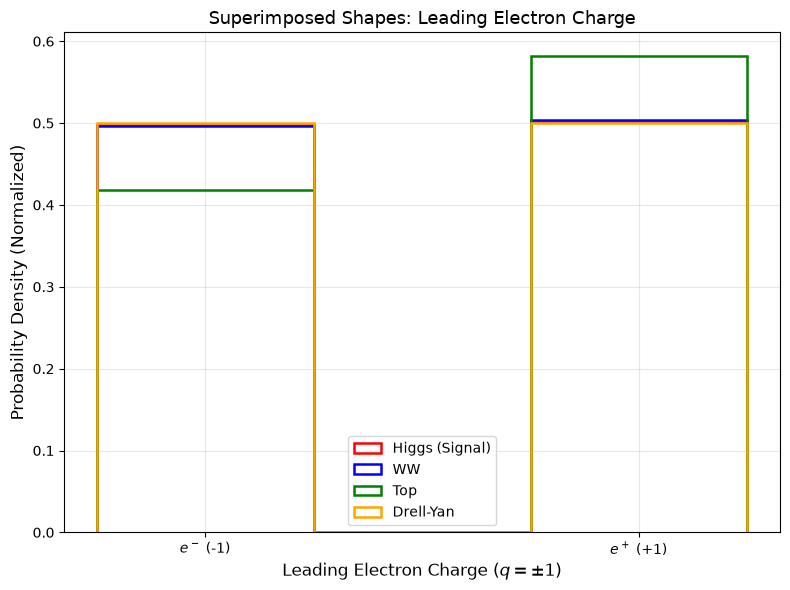

In [47]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Electron_charge"], library="ak", entry_stop=100000)["Electron_charge"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & ((leading == -1) | (leading == 1))
        leading = leading[valid]

        plt.hist(
            leading,
            bins=3,
            range=(-1.5, 1.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Leading Electron Charge ($q = \pm 1$)", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Electron Charge", fontsize=13)
plt.xticks([-1, 1], [r"$e^-$ (-1)", r"$e^+$ (+1)"])
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

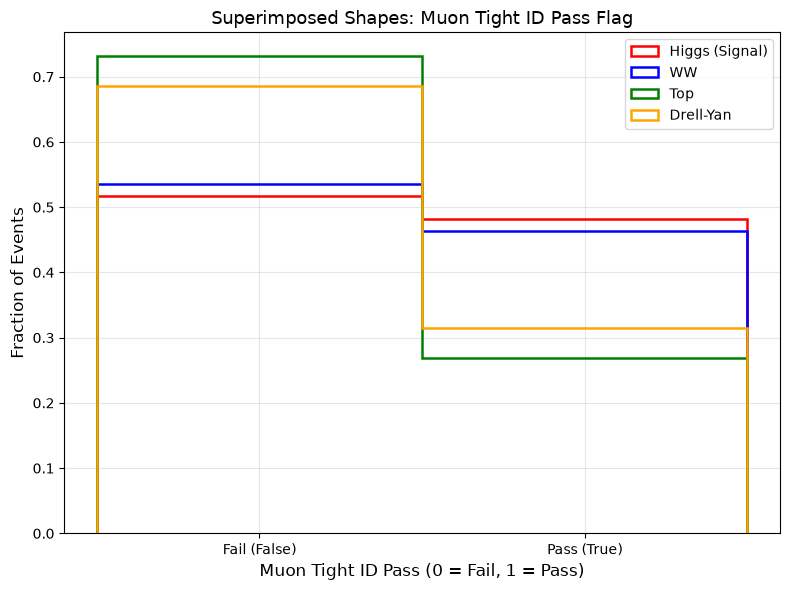

In [48]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Muon_tightId"], library="ak", entry_stop=100000)["Muon_tightId"]
        leading = ak.to_numpy(ak.firsts(arr)).astype(float)
        
        valid = ~np.isnan(leading)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=2,
            range=(-0.5, 1.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Muon Tight ID Pass (0 = Fail, 1 = Pass)", fontsize=12)
plt.ylabel("Fraction of Events", fontsize=12)
plt.title(r"Superimposed Shapes: Muon Tight ID Pass Flag", fontsize=13)
plt.xticks([0, 1], ["Fail (False)", "Pass (True)"])
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

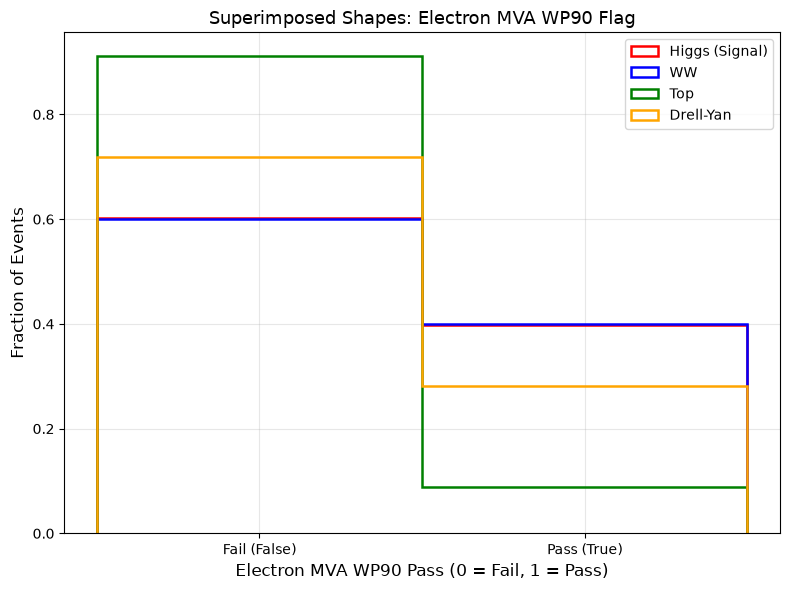

In [49]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Electron_mvaFall17V2Iso_WP90"], library="ak", entry_stop=100000)["Electron_mvaFall17V2Iso_WP90"]
        leading = ak.to_numpy(ak.firsts(arr)).astype(float)
        
        valid = ~np.isnan(leading)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=2,
            range=(-0.5, 1.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Electron MVA WP90 Pass (0 = Fail, 1 = Pass)", fontsize=12)
plt.ylabel("Fraction of Events", fontsize=12)
plt.title(r"Superimposed Shapes: Electron MVA WP90 Flag", fontsize=13)
plt.xticks([0, 1], ["Fail (False)", "Pass (True)"])
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

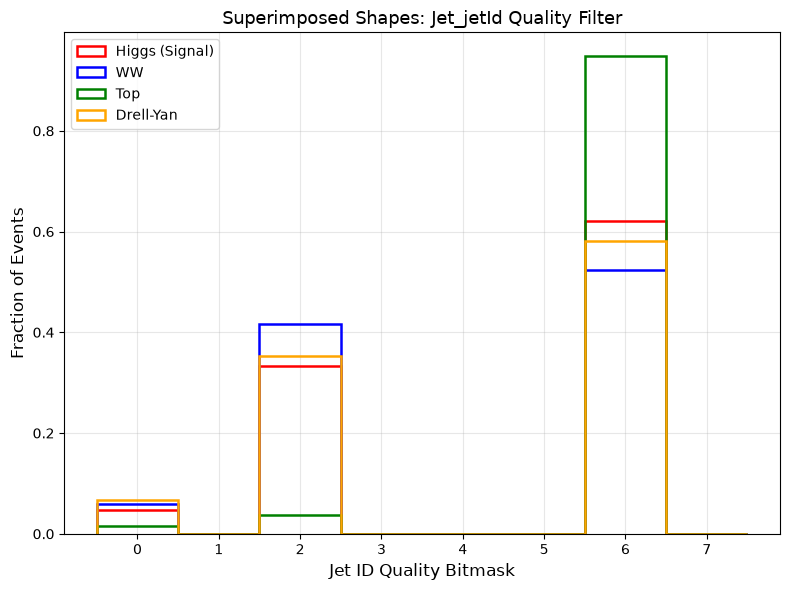

In [50]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Jet_jetId"], library="ak", entry_stop=100000)["Jet_jetId"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= 0) & (leading <= 7)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=8,
            range=(-0.5, 7.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Jet ID Quality Bitmask", fontsize=12)
plt.ylabel("Fraction of Events", fontsize=12)
plt.title(r"Superimposed Shapes: Jet_jetId Quality Filter", fontsize=13)
plt.xticks(range(8))
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

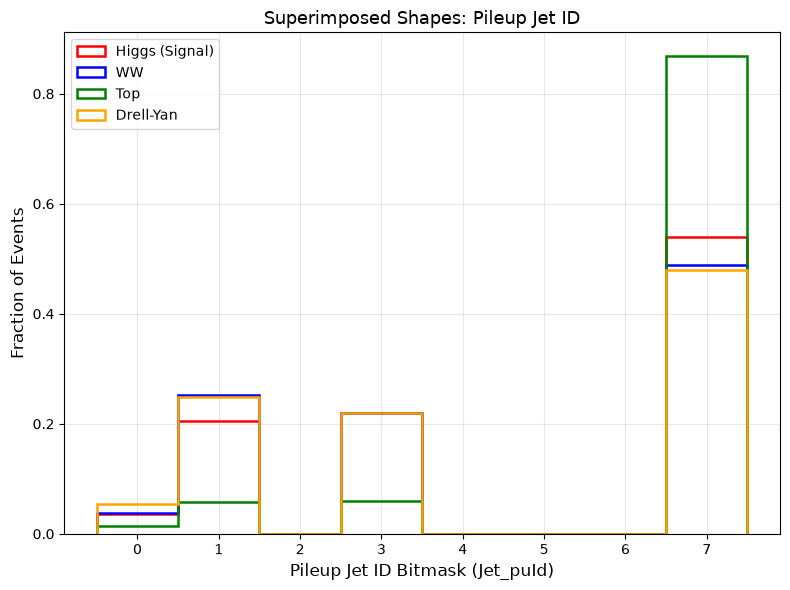

In [51]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    with uproot.open(data_dir / filename) as f:
        tree = f["Events"]
        arr = tree.arrays(["Jet_puId"], library="ak", entry_stop=100000)["Jet_puId"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= 0) & (leading <= 7)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=8,
            range=(-0.5, 7.5),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel("Pileup Jet ID Bitmask (Jet_puId)", fontsize=12)
plt.ylabel("Fraction of Events", fontsize=12)
plt.title(r"Superimposed Shapes: Pileup Jet ID", fontsize=13)
plt.xticks(range(8))
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

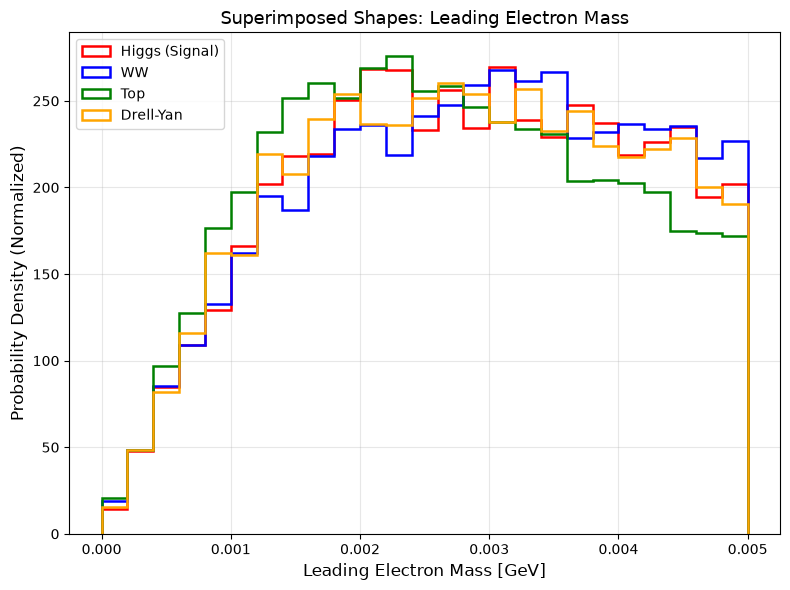

In [52]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        arr = tree.arrays(["Electron_mass"], library="ak", entry_stop=100000)["Electron_mass"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= 0.0) & (leading <= 0.005)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=25,
            range=(0.0, 0.005),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Electron Mass [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Electron Mass", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

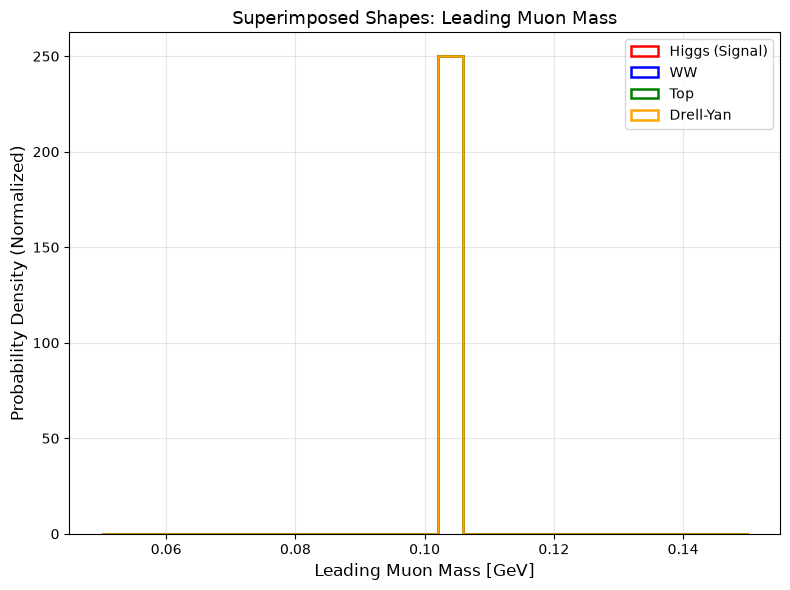

In [53]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path("/data/bvcoe2026/CMS-OD/samples")

samples = {
    "Higgs (Signal)": ("Higgs-train.root", "red"),
    "WW":             ("WW-train.root", "blue"),
    "Top":            ("Top-train.root", "green"),
    "Drell-Yan":      ("DY-train.root", "orange"),
}

plt.figure(figsize=(8, 6))

for label, (filename, color) in samples.items():
    file_path = data_dir / filename
    with uproot.open(file_path) as f:
        tree = f["Events"]
        arr = tree.arrays(["Muon_mass"], library="ak", entry_stop=100000)["Muon_mass"]
        leading = ak.to_numpy(ak.firsts(arr))
        
        valid = ~np.isnan(leading) & (leading >= 0.05) & (leading <= 0.15)
        leading = leading[valid]

        plt.hist(
            leading,
            bins=25,
            range=(0.05, 0.15),
            histtype="step",
            linewidth=1.8,
            density=True,
            label=label,
            color=color
        )

plt.xlabel(r"Leading Muon Mass [GeV]", fontsize=12)
plt.ylabel("Probability Density (Normalized)", fontsize=12)
plt.title(r"Superimposed Shapes: Leading Muon Mass", fontsize=13)
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()